In [3]:
import copy
import gzip
import io
import json
import math
import os
import platform
import random
import subprocess
import sys
import time
from dataclasses import asdict, dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import torchvision
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from torch import nn
from torchvision.datasets import CIFAR10

try:
    from IPython.display import display
except ImportError:  # running as a plain script
    display = print

IN_COLAB = "google.colab" in sys.modules
pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

print("Python:", platform.python_version(), "| PyTorch:", torch.__version__, "| torchvision:", torchvision.__version__)
print("Running in Colab:", IN_COLAB)

Python: 3.13.16 | PyTorch: 2.14.1+cu130 | torchvision: 0.29.1+cu130
Running in Colab: True


In [4]:
if torch.cuda.is_available():
    device = torch.device("cuda")
    DEVICE_NAME = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    try:
        chip = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
    except Exception:
        chip = platform.machine()
    DEVICE_NAME = f"{chip} (MPS)"
else:
    device = torch.device("cpu")
    DEVICE_NAME = f"CPU ({platform.machine()})"

USE_AMP = device.type == "cuda"


def sync():
    """Wait for queued GPU work so wall-clock timings are honest."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "mps":
        torch.mps.synchronize()


def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP)


print("Device:", device, "|", DEVICE_NAME, "| AMP:", USE_AMP)

Device: cuda | Tesla T4 | AMP: True


In [5]:
PROFILES = {
    "smoke": dict(epochs=2, train_limit=2000, val_limit=1000, test_limit=1000, attack_n=64, pgd_steps=3, seed_repeats=1, finetune_epochs=1),
    "local": dict(epochs=8, train_limit=None, val_limit=None, test_limit=None, attack_n=500, pgd_steps=10, seed_repeats=1, finetune_epochs=1),
    "full": dict(epochs=15, train_limit=None, val_limit=None, test_limit=None, attack_n=1000, pgd_steps=10, seed_repeats=2, finetune_epochs=2),
}
# PROFILE = os.environ.get("LAB_PROFILE") or {"cuda": "full", "mps": "local", "cpu": "smoke"}[device.type]
PROFILE = "local"
P = PROFILES[PROFILE]

FORCE_RETRAIN = False     # True = ignore stored runs and train everything again
RUN_CHALLENGES = True     # optional extensions at the end
USE_DRIVE = True          # Colab only: keep artifacts in Google Drive across sessions

print("Profile:", PROFILE, P)

Profile: local {'epochs': 8, 'train_limit': None, 'val_limit': None, 'test_limit': None, 'attack_n': 500, 'pgd_steps': 10, 'seed_repeats': 1, 'finetune_epochs': 1}


In [14]:
if IN_COLAB and USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    ARTIFACT_ROOT = Path("/content/drive/MyDrive/kth-sml-lab1")
else:
    ARTIFACT_ROOT = Path("artifacts")
DATA_DIR = Path("/content/data") if IN_COLAB else Path("data")

ART = ARTIFACT_ROOT / PROFILE
RUN_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR = (ART / d for d in ("runs", "checkpoints", "figures", "cache"))
for d in (RUN_DIR, CKPT_DIR, FIG_DIR, CACHE_DIR, DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Artifacts:", ART.resolve())
print("Data:", DATA_DIR.resolve())

Mounted at /content/drive
Artifacts: /content/drive/MyDrive/kth-sml-lab1/local
Data: /content/data


In [12]:
SPLIT_SEED = 2223
BASE_SEED = 42
CORRUPTION_SEED = 7
ATTACK_SEED = 123

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if device.type == "mps":
        torch.mps.manual_seed(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True, warn_only=True)


set_seed(BASE_SEED)

In [15]:
train_source = CIFAR10(DATA_DIR, train=True, download=True)
test_source = CIFAR10(DATA_DIR, train=False, download=True)
CLASSES = train_source.classes
NUM_CLASSES = len(CLASSES)

X_trainval = torch.from_numpy(train_source.data).permute(0, 3, 1, 2).contiguous()  # uint8 [50000, 3, 32, 32]
y_trainval = torch.tensor(train_source.targets, dtype=torch.long)
X_test_all = torch.from_numpy(test_source.data).permute(0, 3, 1, 2).contiguous()   # uint8 [10000, 3, 32, 32]
y_test_all = torch.tensor(test_source.targets, dtype=torch.long)

print("Provided training images:", tuple(X_trainval.shape), X_trainval.dtype)
print("Provided test images:    ", tuple(X_test_all.shape), X_test_all.dtype)
print("Pixel range:", int(X_trainval.min()), "to", int(X_trainval.max()))
print("Classes:", CLASSES)

assert X_trainval.shape == (50000, 3, 32, 32) and X_test_all.shape == (10000, 3, 32, 32)
assert set(y_trainval.unique().tolist()) == set(range(10))

100%|██████████| 170M/170M [00:26<00:00, 6.38MB/s]


Provided training images: (50000, 3, 32, 32) torch.uint8
Provided test images:     (10000, 3, 32, 32) torch.uint8
Pixel range: 0 to 255
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [16]:
print("Device:", device)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Device: cuda
CUDA available: True
GPU: Tesla T4


In [17]:
class_counts = pd.DataFrame(
    {
        "provided train": np.bincount(y_trainval.numpy(), minlength=10),
        "provided test": np.bincount(y_test_all.numpy(), minlength=10),
    },
    index=CLASSES,
)
display(class_counts)

,provided train,provided test
airplane,5000,1000
automobile,5000,1000
bird,5000,1000
cat,5000,1000
deer,5000,1000
dog,5000,1000
frog,5000,1000
horse,5000,1000
ship,5000,1000
truck,5000,1000


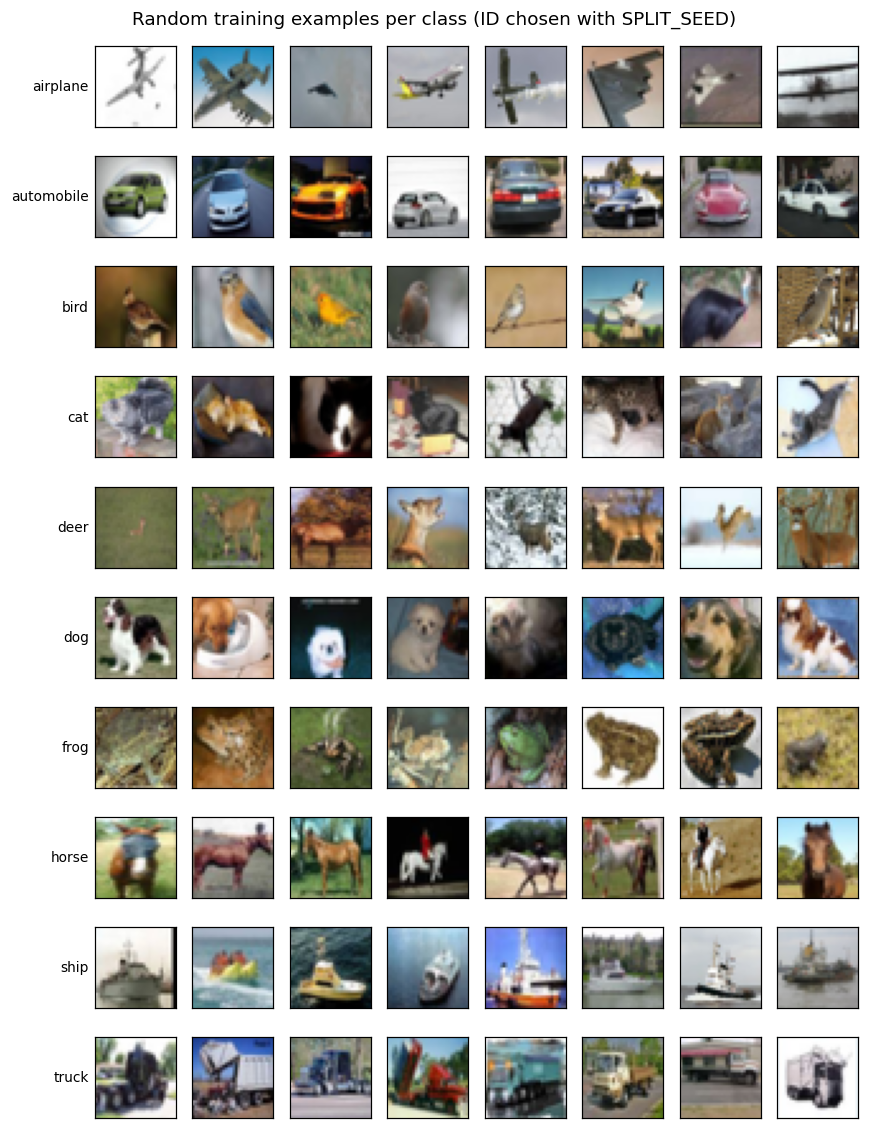

In [18]:
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(8, 10.5))
rng = np.random.default_rng(SPLIT_SEED)
for c in range(NUM_CLASSES):
    picks = rng.choice(np.flatnonzero(y_trainval.numpy() == c), size=8, replace=False)
    for j, idx in enumerate(picks):
        ax = axes[c, j]
        ax.imshow(X_trainval[idx].permute(1, 2, 0).numpy())
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if j == 0:
            ax.set_ylabel(CLASSES[c], rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Random training examples per class (ID chosen with SPLIT_SEED)")
fig.tight_layout()
savefig(fig, "t1_examples")
plt.show()

In [54]:
x01 = X_trainval.float() / 255.0
per_image = pd.DataFrame(
    {
        "class": [CLASSES[i] for i in y_trainval.tolist()],
        "brightness": x01.mean(dim=(1, 2, 3)).numpy(),
        "contrast (pixel std)": x01.std(dim=(1, 2, 3)).numpy(),
        "R": x01[:, 0].mean(dim=(1, 2)).numpy(),
        "G": x01[:, 1].mean(dim=(1, 2)).numpy(),
        "B": x01[:, 2].mean(dim=(1, 2)).numpy(),
    }
)
display(per_image.groupby("class").mean().round(3))
del x01

,brightness,contrast (pixel std),R,G,B
class,,,,,
airplane,0.558,0.204,0.526,0.560,0.589
automobile,0.458,0.237,0.471,0.455,0.447
bird,0.468,0.182,0.489,0.491,0.424
cat,0.456,0.217,0.495,0.456,0.416
deer,0.438,0.179,0.472,0.465,0.378
dog,0.460,0.217,0.500,0.465,0.417
frog,0.418,0.187,0.470,0.438,0.345
horse,0.466,0.221,0.502,0.480,0.417
ship,0.523,0.216,0.490,0.525,0.555


In [53]:
all_ids = np.arange(len(y_trainval))
train_ids, val_ids = train_test_split(
    all_ids, test_size=5000, stratify=y_trainval.numpy(), random_state=SPLIT_SEED
)
test_ids = np.arange(len(y_test_all))


def stratified_limit(ids, labels, limit):
    """Smaller stratified subset for the smoke profile (no-op when limit is None)."""
    if limit is None or limit >= len(ids):
        return ids
    keep, _ = train_test_split(ids, train_size=limit, stratify=labels[ids], random_state=SPLIT_SEED)
    return keep


train_ids = np.sort(stratified_limit(train_ids, y_trainval.numpy(), P["train_limit"]))
val_ids = np.sort(stratified_limit(val_ids, y_trainval.numpy(), P["val_limit"]))
test_ids = np.sort(stratified_limit(test_ids, y_test_all.numpy(), P["test_limit"]))

# A fixed subset of the training split, evaluated without augmentation or dropout, gives a
# deterministic training accuracy of the selected checkpoint (the running accuracy logged during an
# epoch is measured with augmentation/dropout switched on and with changing weights).
train_eval_ids = np.sort(np.random.default_rng(SPLIT_SEED).choice(train_ids, size=min(5000, len(train_ids)), replace=False))

assert not set(train_ids) & set(val_ids)
split_counts = pd.DataFrame(
    {
        "train": np.bincount(y_trainval.numpy()[train_ids], minlength=10),
        "validation": np.bincount(y_trainval.numpy()[val_ids], minlength=10),
        "test": np.bincount(y_test_all.numpy()[test_ids], minlength=10),
    },
    index=CLASSES,
)
split_counts.loc["total"] = split_counts.sum()
display(split_counts)

,train,validation,test
airplane,4500,500,1000
automobile,4500,500,1000
bird,4500,500,1000
cat,4500,500,1000
deer,4500,500,1000
dog,4500,500,1000
frog,4500,500,1000
horse,4500,500,1000
ship,4500,500,1000
truck,4500,500,1000


In [52]:
def channel_stats(images_uint8, chunk=5000):
    total = torch.zeros(3, dtype=torch.float64)
    total_sq = torch.zeros(3, dtype=torch.float64)
    n = 0
    for start in range(0, len(images_uint8), chunk):
        x = images_uint8[start:start + chunk].to(torch.float64) / 255.0
        total += x.sum(dim=(0, 2, 3))
        total_sq += (x ** 2).sum(dim=(0, 2, 3))
        n += x.shape[0] * x.shape[2] * x.shape[3]
    mean = total / n
    std = (total_sq / n - mean ** 2).sqrt()
    return mean.float(), std.float()


CIFAR_MEAN, CIFAR_STD = channel_stats(X_trainval[train_ids])
print("Training-split mean (R, G, B):", CIFAR_MEAN.numpy().round(4))
print("Training-split std  (R, G, B):", CIFAR_STD.numpy().round(4))

Training-split mean (R, G, B): [0.4913 0.4822 0.4464]
Training-split std  (R, G, B): [0.247  0.2434 0.2615]


In [51]:
class TensorData:
    """A split held on the device: uint8 images, labels and the original sample IDs."""

    def __init__(self, images_uint8, labels, ids, name):
        self.x = images_uint8.to(device)
        self.y = labels.to(device)
        self.ids = torch.as_tensor(np.asarray(ids))
        self.name = name

    def __len__(self):
        return len(self.ids)


def iterate(data, batch_size, generator=None):
    """Yield (uint8 images, labels, ids). Shuffled when a generator is given."""
    n = len(data)
    order = torch.randperm(n, generator=generator) if generator is not None else torch.arange(n)
    for start in range(0, n, batch_size):
        idx = order[start:start + batch_size]
        idx_dev = idx.to(device)
        yield data.x[idx_dev], data.y[idx_dev], data.ids[idx]


def to_float(x_uint8):
    return x_uint8.float().div_(255.0)


SPLITS = {
    "train": TensorData(X_trainval[train_ids], y_trainval[train_ids], train_ids, "train"),
    "train_eval": TensorData(X_trainval[train_eval_ids], y_trainval[train_eval_ids], train_eval_ids, "train_eval"),
    "val": TensorData(X_trainval[val_ids], y_trainval[val_ids], val_ids, "val"),
    "test": TensorData(X_test_all[test_ids], y_test_all[test_ids], test_ids, "test"),
}
for k, v in SPLITS.items():
    print(f"{k:>10}: {len(v):>6} images on {v.x.device}")

     train:  45000 images on cuda:0
train_eval:   5000 images on cuda:0
       val:   5000 images on cuda:0
      test:  10000 images on cuda:0


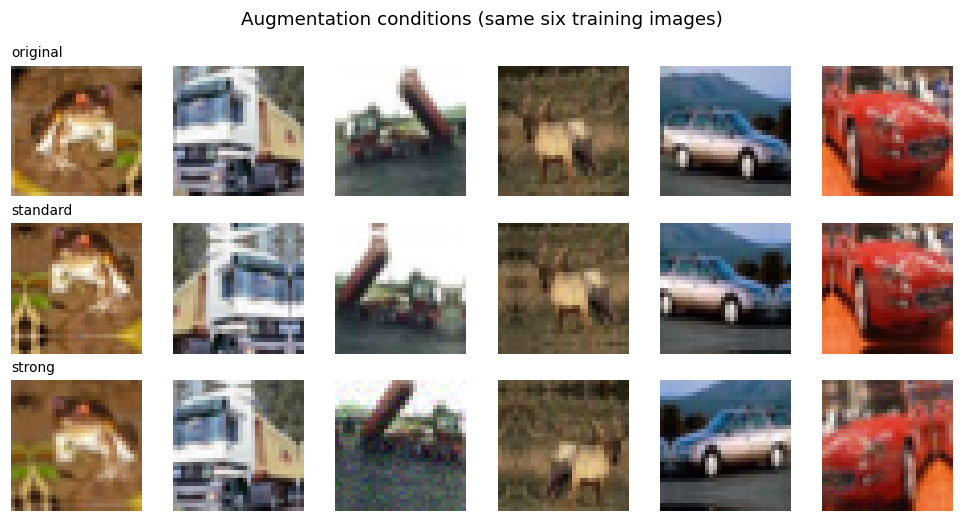

In [23]:
def affine_batch(x, angle_deg, shear_deg=None, scale=None, padding_mode="reflection"):
    """Rotate / shear / scale each image of a [B, 3, H, W] batch around its centre (bilinear)."""
    B = x.shape[0]
    angle = torch.deg2rad(angle_deg.float())
    shear = torch.deg2rad(shear_deg.float()) if shear_deg is not None else torch.zeros(B)
    scale = scale.float() if scale is not None else torch.ones(B)
    cos, sin = torch.cos(angle), torch.sin(angle)
    rot = torch.stack([torch.stack([cos, -sin], -1), torch.stack([sin, cos], -1)], -2)          # [B, 2, 2]
    shr = torch.stack([torch.stack([torch.ones(B), torch.tan(shear)], -1),
                       torch.stack([torch.zeros(B), torch.ones(B)], -1)], -2)
    A = (rot @ shr) / scale[:, None, None]       # maps output coordinates to input coordinates
    theta = torch.cat([A, torch.zeros(B, 2, 1)], dim=2).to(x.device, x.dtype)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode=padding_mode, align_corners=False)


def random_crop_flip(x, gen, pad=4):
    B, C, H, W = x.shape
    padded = F.pad(x, (pad, pad, pad, pad), mode="reflect")
    dy = torch.randint(0, 2 * pad + 1, (B,), generator=gen).to(x.device)
    dx = torch.randint(0, 2 * pad + 1, (B,), generator=gen).to(x.device)
    rows = dy[:, None] + torch.arange(H, device=x.device)[None, :]
    cols = dx[:, None] + torch.arange(W, device=x.device)[None, :]
    out = padded[
        torch.arange(B, device=x.device)[:, None, None, None],
        torch.arange(C, device=x.device)[None, :, None, None],
        rows[:, None, :, None],
        cols[:, None, None, :],
    ]
    flip = (torch.rand(B, generator=gen) < 0.5).to(x.device)
    return torch.where(flip[:, None, None, None], out.flip(3), out)


def augment(x, kind, gen):
    """x: float batch in [0, 1] on the device. gen: CPU generator owned by the run."""
    if kind == "none":
        return x
    x = random_crop_flip(x, gen)
    if kind == "strong":
        B = x.shape[0]
        apply = (torch.rand(B, generator=gen) < 0.5).float()
        angle = (torch.rand(B, generator=gen) * 2 - 1) * 15 * apply
        shear = (torch.rand(B, generator=gen) * 2 - 1) * 10 * apply
        x = affine_batch(x, angle, shear)
        sigma = torch.rand(B, generator=gen) * 0.06 * (torch.rand(B, generator=gen) < 0.5).float()
        noise = torch.randn(x.shape, generator=gen) * sigma[:, None, None, None]
        x = (x + noise.to(x.device)).clamp_(0, 1)
    elif kind != "standard":
        raise ValueError(kind)
    return x


demo_gen = torch.Generator().manual_seed(0)
demo = to_float(SPLITS["train"].x[:6])
rows = {"original": demo, "standard": augment(demo, "standard", demo_gen), "strong": augment(demo, "strong", demo_gen)}
fig, axes = plt.subplots(3, 6, figsize=(9, 4.8))
for r, (title, batch) in enumerate(rows.items()):
    for j in range(6):
        axes[r, j].imshow(batch[j].permute(1, 2, 0).cpu().numpy())
        axes[r, j].axis("off")
    axes[r, 0].set_title(title, loc="left", fontsize=9)
fig.suptitle("Augmentation conditions (same six training images)")
fig.tight_layout()
savefig(fig, "t1_augmentations")
plt.show()

In [74]:
class AlexNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 192, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4096, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [75]:
model = AlexNet().to(device)

# Create 2 dummy CIFAR-10 images
x = torch.randn(2, 3, 32, 32).to(device)

# Test forward propagation
with torch.no_grad():
    output = model(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([2, 3, 32, 32])
Output shape: torch.Size([2, 10])


In [76]:
# Loss function for 10-class classification
criterion = nn.CrossEntropyLoss()

# Optimizer for updating weights
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0.9,
    weight_decay=0.0005
)

In [77]:
BATCH_SIZE = 64
EPOCHS = P["epochs"]

# RGB statistics from Task 1
mean = CIFAR_MEAN.to(device).view(1, 3, 1, 1)
std = CIFAR_STD.to(device).view(1, 3, 1, 1)

gen = torch.Generator().manual_seed(BASE_SEED)
alexnet_history = []

model.train()

for epoch in range(EPOCHS):
    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels, ids in iterate(
        SPLITS["train"], BATCH_SIZE, generator=gen
    ):
        # Prepare images
        images = to_float(images)
        images = (images - mean) / std

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        total_loss += loss.item() * len(labels)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += len(labels)

    train_loss = total_loss / total
    train_accuracy = 100 * correct / total

    alexnet_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy
    })


    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Loss: {total_loss / total:.4f} | "
        f"Train Accuracy: {100 * correct / total:.2f}%"
    )

Epoch 1/8 | Loss: 1.9870 | Train Accuracy: 24.24%
Epoch 2/8 | Loss: 1.4815 | Train Accuracy: 44.54%
Epoch 3/8 | Loss: 1.2006 | Train Accuracy: 56.40%
Epoch 4/8 | Loss: 0.9903 | Train Accuracy: 65.02%
Epoch 5/8 | Loss: 0.8366 | Train Accuracy: 70.71%
Epoch 6/8 | Loss: 0.7272 | Train Accuracy: 74.62%
Epoch 7/8 | Loss: 0.6279 | Train Accuracy: 78.44%
Epoch 8/8 | Loss: 0.5447 | Train Accuracy: 81.28%


In [78]:
    # Validation after each epoch
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels, ids in iterate(SPLITS["val"], BATCH_SIZE):
            images = (to_float(images) - mean) / std
            outputs = model(images)

            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += len(labels)

    val_accuracy = 100 * val_correct / val_total

    alexnet_history.append({
        "epoch": epoch + 1,
        "train_loss": total_loss / total,
        "train_accuracy": 100 * correct / total,
        "val_accuracy": val_accuracy
    })

    model.train()

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU()
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=1024, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=1024, out_features=512, bias

Save Trained AlexNet

Cell 6 — Implement ResNet-18

In [64]:
alexnet_history = pd.DataFrame(alexnet_history)
torch.save(
    model.state_dict(),
    CKPT_DIR / "alexnet_8epochs.pt"
)

print("AlexNet model saved successfully!")

AlexNet model saved successfully!


In [80]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.relu = nn.ReLU(inplace=True)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels, 1,
                    stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)

        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        out = self.relu(out + identity)
        return out


class ResNet18(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.initial = nn.Sequential(
            nn.Conv2d(3, 64, 3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True)
        )

        self.stage1 = nn.Sequential(
            BasicBlock(64, 64),
            BasicBlock(64, 64)
        )

        self.stage2 = nn.Sequential(
            BasicBlock(64, 128, stride=2),
            BasicBlock(128, 128)
        )

        self.stage3 = nn.Sequential(
            BasicBlock(128, 256, stride=2),
            BasicBlock(256, 256)
        )

        self.stage4 = nn.Sequential(
            BasicBlock(256, 512, stride=2),
            BasicBlock(512, 512)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.initial(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)

        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)

Cell 7 — Check both architectures

In [81]:
def count_parameters(model):
    return sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )


for name, ModelClass in [
    ("AlexNet", AlexNet),
    ("ResNet18", ResNet18)
]:
    check_model = ModelClass().to(device)
    check_model.eval()

    with torch.no_grad():
        dummy = torch.zeros(2, 3, 32, 32, device=device)
        output = check_model(dummy)

    print(
        name,
        "Output:", tuple(output.shape),
        "Parameters:", count_parameters(check_model)
    )

    assert output.shape == (2, 10)

    del check_model

AlexNet Output: (2, 10) Parameters: 6976842
ResNet18 Output: (2, 10) Parameters: 11173962


Cell 8 — Reusable training and validation

In [82]:

import copy
import time
import pandas as pd
import torch
from torch import nn

BATCH_SIZE = 64
EPOCHS = P["epochs"]

mean = CIFAR_MEAN.to(device).view(1, 3, 1, 1)
std = CIFAR_STD.to(device).view(1, 3, 1, 1)


def prepare_batch(images):
    images = to_float(images)
    return (images - mean) / std


def run_epoch(model, dataset, criterion, optimizer=None, gen=None,augmentation="none"):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels, ids in iterate(
        dataset,
        BATCH_SIZE,
        generator=gen if training else None
    ):
        # images = prepare_batch(images)
        images = to_float(images)

        if training and augmentation != "none":
            images = augment(images, augmentation, gen)

        images = (images - mean) / std

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return {
        "loss": total_loss / total,
        "accuracy": 100 * correct / total
    }


def reset_peak_memory():
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    elif device.type == "mps":
        if hasattr(torch.mps, "reset_peak_memory_stats"):
            torch.mps.reset_peak_memory_stats()


def get_peak_memory_mb():
    if device.type == "cuda":
        return torch.cuda.max_memory_allocated(device) / (1024 ** 2)

    elif device.type == "mps":
        if hasattr(torch.mps, "max_memory_allocated"):
            return torch.mps.max_memory_allocated() / (1024 ** 2)
        return None

    return None


def train_model(name, model, epochs,weight_decay=0.0005,augmentation="none"):
    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=0.01,
        momentum=0.9,
        weight_decay=weight_decay
    )

    gen = torch.Generator().manual_seed(BASE_SEED)

    best_path = CKPT_DIR / f"{name}_best.pt"
    last_path = CKPT_DIR / f"{name}_last.pt"

    history = []
    best_accuracy = -1.0
    start_epoch = 0

    # ---------------------------------
    # Automatically resume training
    # ---------------------------------
    if last_path.exists() and not FORCE_RETRAIN:
        checkpoint = torch.load(
            last_path,
            map_location=device,
            weights_only=True
        )

        if checkpoint.get("profile") != PROFILE:
            raise ValueError("Checkpoint profile does not match.")

        model.load_state_dict(checkpoint["model_state"])
        optimizer.load_state_dict(checkpoint["optimizer_state"])

        history = checkpoint["history"]
        start_epoch = checkpoint["epoch"]

        if history:
            best_accuracy = max(
                row["val_accuracy"] for row in history
            )

        if "generator_state" in checkpoint:
            gen.set_state(
             checkpoint["generator_state"].cpu().byte()
            )

        print(f"{name}: Resuming from epoch {start_epoch + 1}")

    else:
        print(f"{name}: Starting new training")

    # ---------------------------------
    # Train remaining epochs
    # ---------------------------------
    for epoch in range(start_epoch, epochs):

        sync()
        reset_peak_memory()
        start = time.perf_counter()

        train_metrics = run_epoch(
            model,
            SPLITS["train"],
            criterion,
            optimizer=optimizer,
            gen=gen,
            augmentation=augmentation
        )

        val_metrics = run_epoch(
            model,
            SPLITS["val"],
            criterion
        )

        sync()
        duration = time.perf_counter() - start
        peak_memory = get_peak_memory_mb()

        row = {
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "seconds": duration,
            "peak_memory_mb": peak_memory
        }

        history.append(row)

        checkpoint = {
            "epoch": epoch + 1,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "history": history,
            "profile": PROFILE,
            "generator_state": gen.get_state()
        }

        # Save latest checkpoint
        torch.save(checkpoint, last_path)

        # Save best validation checkpoint
        if val_metrics["accuracy"] > best_accuracy:
            best_accuracy = val_metrics["accuracy"]
            torch.save(checkpoint, best_path)

        memory_text = (
            f"{peak_memory:.1f} MB"
            if peak_memory is not None
            else "N/A"
        )

        print(
            f"{name} | Epoch {epoch + 1}/{epochs} | "
            f"Train: {train_metrics['accuracy']:.2f}% | "
            f"Val: {val_metrics['accuracy']:.2f}% | "
            f"Time: {duration:.1f}s | "
            f"Peak GPU Memory: {memory_text}"
        )

    # ---------------------------------
    # Load best model for evaluation
    # ---------------------------------
    if best_path.exists():
        best_checkpoint = torch.load(
            best_path,
            map_location=device,
            weights_only=True
        )

        model.load_state_dict(
            best_checkpoint["model_state"]
        )

        print(
            f"{name}: Loaded best checkpoint "
            f"(epoch {best_checkpoint['epoch']})"
        )

    return model, pd.DataFrame(history)


Cell 9 — Train and compare both models

In [83]:
# 1. Load previously trained AlexNet
alexnet = AlexNet().to(device)

alexnet.load_state_dict(
    torch.load(
        CKPT_DIR / "alexnet_8epochs.pt",
        map_location=device,
        weights_only=True
    )
)

alexnet.eval()
print("AlexNet loaded successfully!")


# 2. Train ResNet-18
set_seed(BASE_SEED)

resnet, resnet_history = train_model(
    "resnet18",
    ResNet18(),
    EPOCHS
)

print("ResNet-18 training completed!")

AlexNet loaded successfully!
resnet18: Resuming from epoch 9
resnet18: Loaded best checkpoint (epoch 8)
ResNet-18 training completed!


Cell 10- Compare Results

In [84]:
comparison = pd.DataFrame([
    {
        "Model": "AlexNet",
        "Parameters": count_parameters(alexnet),
        "Best Val Accuracy": 0.8020,
        "Training Time (s)": None,
        "Trained Samples": len(SPLITS["train"]) * 8
    },
    {
        "Model": "ResNet18",
        "Parameters": count_parameters(resnet),
        "Best Val Accuracy": resnet_history["val_accuracy"].max() / 100,
        "Training Time (s)": resnet_history["seconds"].sum(),
        "Trained Samples": len(SPLITS["train"]) * EPOCHS
    }
])

display(comparison)

,Model,Parameters,Best Val Accuracy,Training Time (s),Trained Samples
0,AlexNet,6976842,0.8020,NaN,360000
1,ResNet18,11173962,0.8098,4363.2039,360000


In [66]:
print(alexnet_history.head())
print(alexnet_history.columns.tolist())

   epoch  train_loss  train_accuracy  val_loss  val_accuracy
0      1      1.9975         24.2356    1.5549         42.04
1      2      1.4606         45.2756    1.2538         54.12
2      3      1.1756         57.5467    1.0650         61.48
3      4      0.9668         65.6956    0.9036         68.60
4      5      0.8172         71.3622    0.7623         73.18
['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']


Cell 11 — Visualize the learning curves

AlexNet columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy']
ResNet columns: ['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'seconds', 'peak_memory_mb']


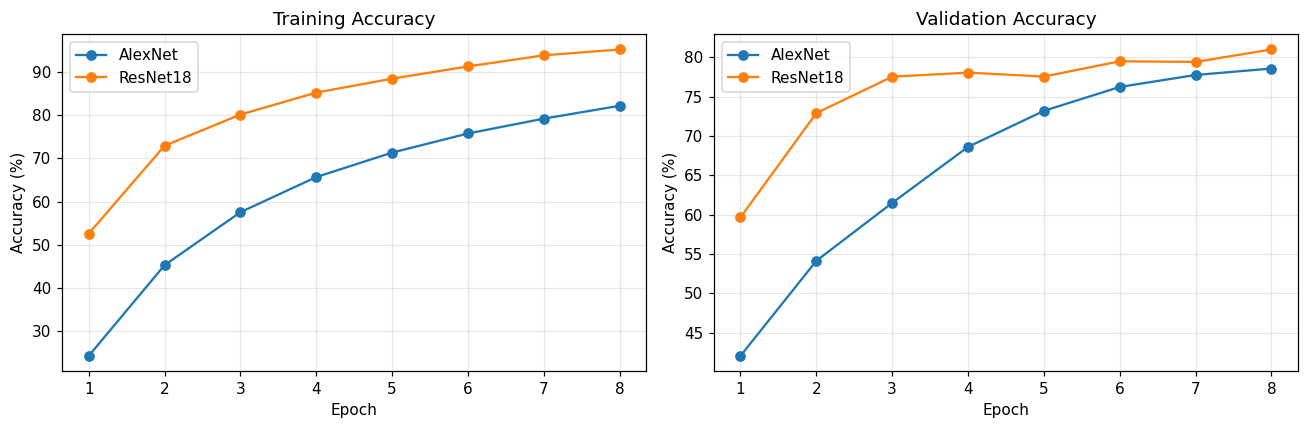

In [67]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert histories to DataFrames if needed
alexnet_history = pd.DataFrame(alexnet_history)
resnet_history = pd.DataFrame(resnet_history)

print("AlexNet columns:", alexnet_history.columns.tolist())
print("ResNet columns:", resnet_history.columns.tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Training accuracy
for name, history in [
    ("AlexNet", alexnet_history),
    ("ResNet18", resnet_history)
]:
    axes[0].plot(
        history["epoch"],
        history["train_accuracy"],
        marker="o",
        label=name
    )

# Validation accuracy (only if recorded)
for name, history in [
    ("AlexNet", alexnet_history),
    ("ResNet18", resnet_history)
]:
    if "val_accuracy" in history.columns:
        axes[1].plot(
            history["epoch"],
            history["val_accuracy"],
            marker="o",
            label=name
        )

axes[0].set_title("Training Accuracy")
axes[1].set_title("Validation Accuracy")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
savefig(fig, "t2_accuracy_comparison")
plt.show()

Cell 12 — Final test evaluation

In [68]:
criterion = nn.CrossEntropyLoss()

for name, trained_model in [
    ("AlexNet", alexnet),
    ("ResNet18", resnet)
]:
    metrics = run_epoch(
        trained_model,
        SPLITS["test"],
        criterion
    )

    print(
        f"{name} | "
        f"Test Accuracy: {metrics['accuracy']:.2f}% | "
        f"Test Loss: {metrics['loss']:.4f}"
    )

AlexNet | Test Accuracy: 78.71% | Test Loss: 0.6483
ResNet18 | Test Accuracy: 81.00% | Test Loss: 0.6650


Task 3 - Model Capacity

In [6]:
class AlexNet3(nn.Module):
    def __init__(self, fc1=1024, fc2=512, dropout=0.5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 192, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(192, 384, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(4096, fc1),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(fc1, fc2),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(fc2, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [9]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Check capacity

In [10]:
small = AlexNet3(fc1=256, fc2=128)
baseline = AlexNet3(fc1=1024, fc2=512)
large = AlexNet3(fc1=2048, fc2=1024)

print("Small:", count_parameters(small))
print("Baseline:", count_parameters(baseline))
print("Large:", count_parameters(large))

Small: 3334602
Baseline: 6976842
Large: 12750666


Train the small AlexNet

In [28]:
set_seed(BASE_SEED)

small_model, small_history = train_model(
    "t3_alexnet_small",
    AlexNet3(fc1=256, fc2=128, dropout=0.5),
    EPOCHS
)

t3_alexnet_small: Starting new training
t3_alexnet_small | Epoch 1/8 | Train: 22.01% | Val: 37.82% | Time: 10.7s | Peak GPU Memory: 394.6 MB
t3_alexnet_small | Epoch 2/8 | Train: 40.33% | Val: 50.46% | Time: 8.0s | Peak GPU Memory: 394.8 MB
t3_alexnet_small | Epoch 3/8 | Train: 51.99% | Val: 60.56% | Time: 8.1s | Peak GPU Memory: 394.9 MB
t3_alexnet_small | Epoch 4/8 | Train: 60.48% | Val: 64.04% | Time: 8.3s | Peak GPU Memory: 396.4 MB
t3_alexnet_small | Epoch 5/8 | Train: 66.24% | Val: 69.06% | Time: 8.2s | Peak GPU Memory: 394.9 MB
t3_alexnet_small | Epoch 6/8 | Train: 70.76% | Val: 72.54% | Time: 8.3s | Peak GPU Memory: 395.6 MB
t3_alexnet_small | Epoch 7/8 | Train: 74.44% | Val: 73.24% | Time: 8.4s | Peak GPU Memory: 394.9 MB
t3_alexnet_small | Epoch 8/8 | Train: 77.20% | Val: 76.72% | Time: 8.7s | Peak GPU Memory: 395.6 MB
t3_alexnet_small: Loaded best checkpoint (epoch 8)


Train Baseline AlexNet

In [29]:
set_seed(BASE_SEED)

baseline_model, baseline_history = train_model(
    "t3_alexnet_baseline",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS
)

t3_alexnet_baseline: Starting new training
t3_alexnet_baseline | Epoch 1/8 | Train: 24.24% | Val: 42.04% | Time: 11.2s | Peak GPU Memory: 465.0 MB
t3_alexnet_baseline | Epoch 2/8 | Train: 45.28% | Val: 54.12% | Time: 11.3s | Peak GPU Memory: 465.6 MB
t3_alexnet_baseline | Epoch 3/8 | Train: 57.55% | Val: 61.48% | Time: 9.6s | Peak GPU Memory: 465.3 MB
t3_alexnet_baseline | Epoch 4/8 | Train: 65.70% | Val: 68.60% | Time: 9.4s | Peak GPU Memory: 465.6 MB
t3_alexnet_baseline | Epoch 5/8 | Train: 71.36% | Val: 73.18% | Time: 9.6s | Peak GPU Memory: 465.9 MB
t3_alexnet_baseline | Epoch 6/8 | Train: 75.80% | Val: 76.22% | Time: 10.0s | Peak GPU Memory: 465.6 MB
t3_alexnet_baseline | Epoch 7/8 | Train: 79.24% | Val: 77.74% | Time: 9.4s | Peak GPU Memory: 466.1 MB
t3_alexnet_baseline | Epoch 8/8 | Train: 82.22% | Val: 78.56% | Time: 9.7s | Peak GPU Memory: 465.6 MB
t3_alexnet_baseline: Loaded best checkpoint (epoch 8)


Train Large AlexNet

In [31]:
set_seed(BASE_SEED)

large_model, large_history = train_model(
    "t3_alexnet_large",
    AlexNet3(fc1=2048, fc2=1024, dropout=0.5),
    EPOCHS
)

t3_alexnet_large: Starting new training
t3_alexnet_large | Epoch 1/8 | Train: 25.79% | Val: 44.14% | Time: 12.0s | Peak GPU Memory: 583.8 MB
t3_alexnet_large | Epoch 2/8 | Train: 47.41% | Val: 55.34% | Time: 12.3s | Peak GPU Memory: 583.8 MB
t3_alexnet_large | Epoch 3/8 | Train: 59.05% | Val: 63.08% | Time: 10.7s | Peak GPU Memory: 583.8 MB
t3_alexnet_large | Epoch 4/8 | Train: 68.04% | Val: 69.64% | Time: 10.5s | Peak GPU Memory: 583.8 MB
t3_alexnet_large | Epoch 5/8 | Train: 73.04% | Val: 73.84% | Time: 10.6s | Peak GPU Memory: 583.8 MB
t3_alexnet_large | Epoch 6/8 | Train: 77.17% | Val: 78.24% | Time: 10.8s | Peak GPU Memory: 583.8 MB
t3_alexnet_large | Epoch 7/8 | Train: 80.51% | Val: 77.94% | Time: 10.9s | Peak GPU Memory: 583.8 MB
t3_alexnet_large | Epoch 8/8 | Train: 83.42% | Val: 79.06% | Time: 11.4s | Peak GPU Memory: 583.8 MB
t3_alexnet_large: Loaded best checkpoint (epoch 8)


Plot the capacity comparison

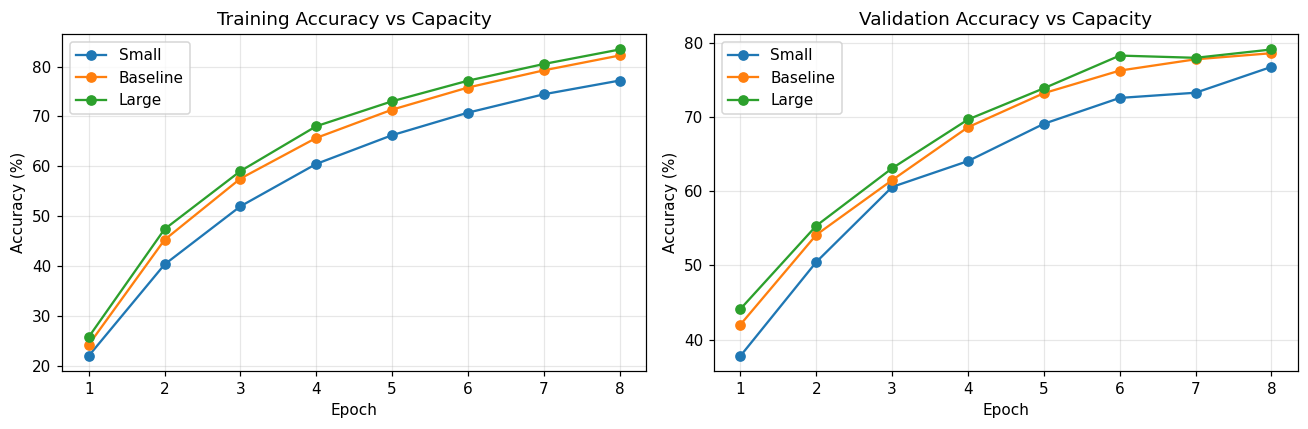

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

histories = {
    "Small": small_history,
    "Baseline": baseline_history,
    "Large": large_history
}

for name, history in histories.items():
    axes[0].plot(
        history["epoch"],
        history["train_accuracy"],
        marker="o",
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["val_accuracy"],
        marker="o",
        label=name
    )

axes[0].set_title("Training Accuracy vs Capacity")
axes[1].set_title("Validation Accuracy vs Capacity")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t3_capacity_accuracy")
plt.show()

Plot training and validation loss

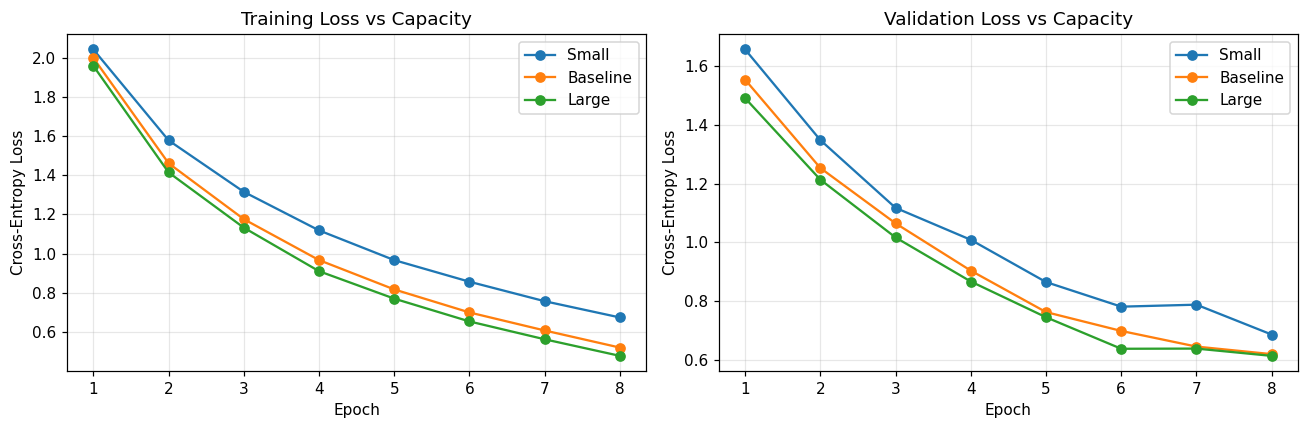

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in histories.items():
    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        marker="o",
        label=name
    )

    axes[1].plot(
        history["epoch"],
        history["val_loss"],
        marker="o",
        label=name
    )

axes[0].set_title("Training Loss vs Capacity")
axes[1].set_title("Validation Loss vs Capacity")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t3_capacity_loss")
plt.show()

Train without L2 regularization

In [37]:
set_seed(BASE_SEED)

no_l2_model, no_l2_history = train_model(
    "t3_alexnet_no_l2",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS,
    weight_decay=0.0
)

t3_alexnet_no_l2: Starting new training
t3_alexnet_no_l2 | Epoch 1/8 | Train: 24.29% | Val: 42.32% | Time: 9.6s | Peak GPU Memory: 615.7 MB
t3_alexnet_no_l2 | Epoch 2/8 | Train: 45.92% | Val: 54.80% | Time: 11.5s | Peak GPU Memory: 617.8 MB
t3_alexnet_no_l2 | Epoch 3/8 | Train: 58.46% | Val: 63.16% | Time: 9.3s | Peak GPU Memory: 615.7 MB
t3_alexnet_no_l2 | Epoch 4/8 | Train: 66.88% | Val: 70.08% | Time: 9.1s | Peak GPU Memory: 617.8 MB
t3_alexnet_no_l2 | Epoch 5/8 | Train: 72.70% | Val: 74.68% | Time: 9.0s | Peak GPU Memory: 615.7 MB
t3_alexnet_no_l2 | Epoch 6/8 | Train: 77.02% | Val: 75.34% | Time: 8.9s | Peak GPU Memory: 617.8 MB
t3_alexnet_no_l2 | Epoch 7/8 | Train: 80.72% | Val: 78.44% | Time: 8.9s | Peak GPU Memory: 615.7 MB
t3_alexnet_no_l2 | Epoch 8/8 | Train: 83.92% | Val: 79.94% | Time: 9.0s | Peak GPU Memory: 617.8 MB
t3_alexnet_no_l2: Loaded best checkpoint (epoch 8)


Stronger L2 regularization

In [39]:
set_seed(BASE_SEED)

strong_l2_model, strong_l2_history = train_model(
    "t3_alexnet_strong_l2",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS,
    weight_decay=0.005
)

t3_alexnet_strong_l2: Starting new training
t3_alexnet_strong_l2 | Epoch 1/8 | Train: 20.70% | Val: 37.40% | Time: 10.7s | Peak GPU Memory: 671.5 MB
t3_alexnet_strong_l2 | Epoch 2/8 | Train: 39.47% | Val: 44.40% | Time: 11.7s | Peak GPU Memory: 671.7 MB
t3_alexnet_strong_l2 | Epoch 3/8 | Train: 48.19% | Val: 53.90% | Time: 9.6s | Peak GPU Memory: 671.7 MB
t3_alexnet_strong_l2 | Epoch 4/8 | Train: 55.17% | Val: 58.84% | Time: 9.4s | Peak GPU Memory: 671.7 MB
t3_alexnet_strong_l2 | Epoch 5/8 | Train: 59.24% | Val: 60.48% | Time: 9.6s | Peak GPU Memory: 671.7 MB
t3_alexnet_strong_l2 | Epoch 6/8 | Train: 62.70% | Val: 65.16% | Time: 9.3s | Peak GPU Memory: 671.7 MB
t3_alexnet_strong_l2 | Epoch 7/8 | Train: 65.54% | Val: 64.44% | Time: 9.3s | Peak GPU Memory: 671.7 MB
t3_alexnet_strong_l2 | Epoch 8/8 | Train: 67.64% | Val: 69.28% | Time: 9.6s | Peak GPU Memory: 671.7 MB
t3_alexnet_strong_l2: Loaded best checkpoint (epoch 8)


Plot L2 accuracy and loss

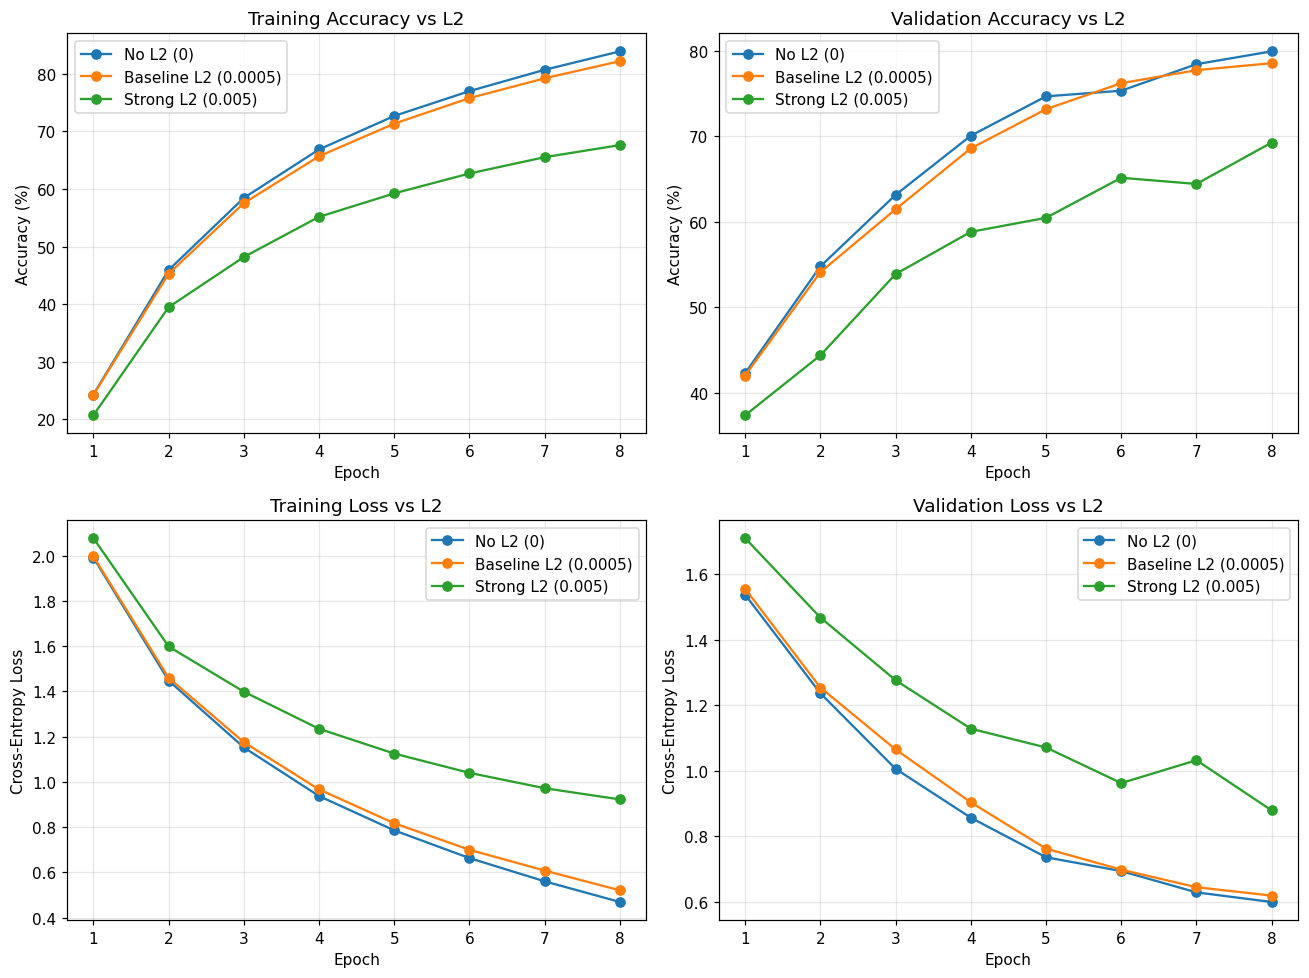

In [40]:
l2_histories = {
    "No L2 (0)": no_l2_history,
    "Baseline L2 (0.0005)": baseline_history,
    "Strong L2 (0.005)": strong_l2_history
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for name, history in l2_histories.items():
    axes[0, 0].plot(history["epoch"], history["train_accuracy"], marker="o", label=name)
    axes[0, 1].plot(history["epoch"], history["val_accuracy"], marker="o", label=name)
    axes[1, 0].plot(history["epoch"], history["train_loss"], marker="o", label=name)
    axes[1, 1].plot(history["epoch"], history["val_loss"], marker="o", label=name)

axes[0, 0].set_title("Training Accuracy vs L2")
axes[0, 1].set_title("Validation Accuracy vs L2")
axes[1, 0].set_title("Training Loss vs L2")
axes[1, 1].set_title("Validation Loss vs L2")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)" if "Accuracy" in ax.get_title() else "Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t3_l2_comparison")
plt.show()

Train without dropout

In [41]:
set_seed(BASE_SEED)

no_dropout_model, no_dropout_history = train_model(
    "t3_alexnet_dropout_0",
    AlexNet3(fc1=1024, fc2=512, dropout=0.0),
    EPOCHS,
    weight_decay=0.0005
)

t3_alexnet_dropout_0: Starting new training
t3_alexnet_dropout_0 | Epoch 1/8 | Train: 27.38% | Val: 44.10% | Time: 10.1s | Peak GPU Memory: 724.4 MB
t3_alexnet_dropout_0 | Epoch 2/8 | Train: 49.68% | Val: 53.84% | Time: 10.3s | Peak GPU Memory: 724.5 MB
t3_alexnet_dropout_0 | Epoch 3/8 | Train: 61.22% | Val: 65.02% | Time: 9.7s | Peak GPU Memory: 724.8 MB
t3_alexnet_dropout_0 | Epoch 4/8 | Train: 70.10% | Val: 69.62% | Time: 9.8s | Peak GPU Memory: 724.5 MB
t3_alexnet_dropout_0 | Epoch 5/8 | Train: 74.90% | Val: 74.98% | Time: 9.4s | Peak GPU Memory: 724.8 MB
t3_alexnet_dropout_0 | Epoch 6/8 | Train: 79.01% | Val: 77.34% | Time: 9.3s | Peak GPU Memory: 724.5 MB
t3_alexnet_dropout_0 | Epoch 7/8 | Train: 82.52% | Val: 78.64% | Time: 9.7s | Peak GPU Memory: 724.8 MB
t3_alexnet_dropout_0 | Epoch 8/8 | Train: 85.37% | Val: 77.64% | Time: 9.6s | Peak GPU Memory: 724.5 MB
t3_alexnet_dropout_0: Loaded best checkpoint (epoch 7)


Step 3 — Train with dropout 0.3

In [42]:
set_seed(BASE_SEED)

dropout_03_model, dropout_03_history = train_model(
    "t3_alexnet_dropout_03",
    AlexNet3(fc1=1024, fc2=512, dropout=0.3),
    EPOCHS,
    weight_decay=0.0005
)

t3_alexnet_dropout_03: Starting new training
t3_alexnet_dropout_03 | Epoch 1/8 | Train: 26.05% | Val: 44.12% | Time: 9.9s | Peak GPU Memory: 779.3 MB
t3_alexnet_dropout_03 | Epoch 2/8 | Train: 47.89% | Val: 53.48% | Time: 10.1s | Peak GPU Memory: 779.0 MB
t3_alexnet_dropout_03 | Epoch 3/8 | Train: 59.47% | Val: 62.90% | Time: 9.7s | Peak GPU Memory: 778.3 MB
t3_alexnet_dropout_03 | Epoch 4/8 | Train: 67.85% | Val: 68.82% | Time: 9.5s | Peak GPU Memory: 778.1 MB
t3_alexnet_dropout_03 | Epoch 5/8 | Train: 73.27% | Val: 74.18% | Time: 9.4s | Peak GPU Memory: 778.1 MB
t3_alexnet_dropout_03 | Epoch 6/8 | Train: 77.16% | Val: 75.84% | Time: 9.3s | Peak GPU Memory: 778.1 MB
t3_alexnet_dropout_03 | Epoch 7/8 | Train: 80.55% | Val: 78.46% | Time: 9.4s | Peak GPU Memory: 778.1 MB
t3_alexnet_dropout_03 | Epoch 8/8 | Train: 83.53% | Val: 78.22% | Time: 9.5s | Peak GPU Memory: 778.1 MB
t3_alexnet_dropout_03: Loaded best checkpoint (epoch 7)


Plot dropout accuracy and loss

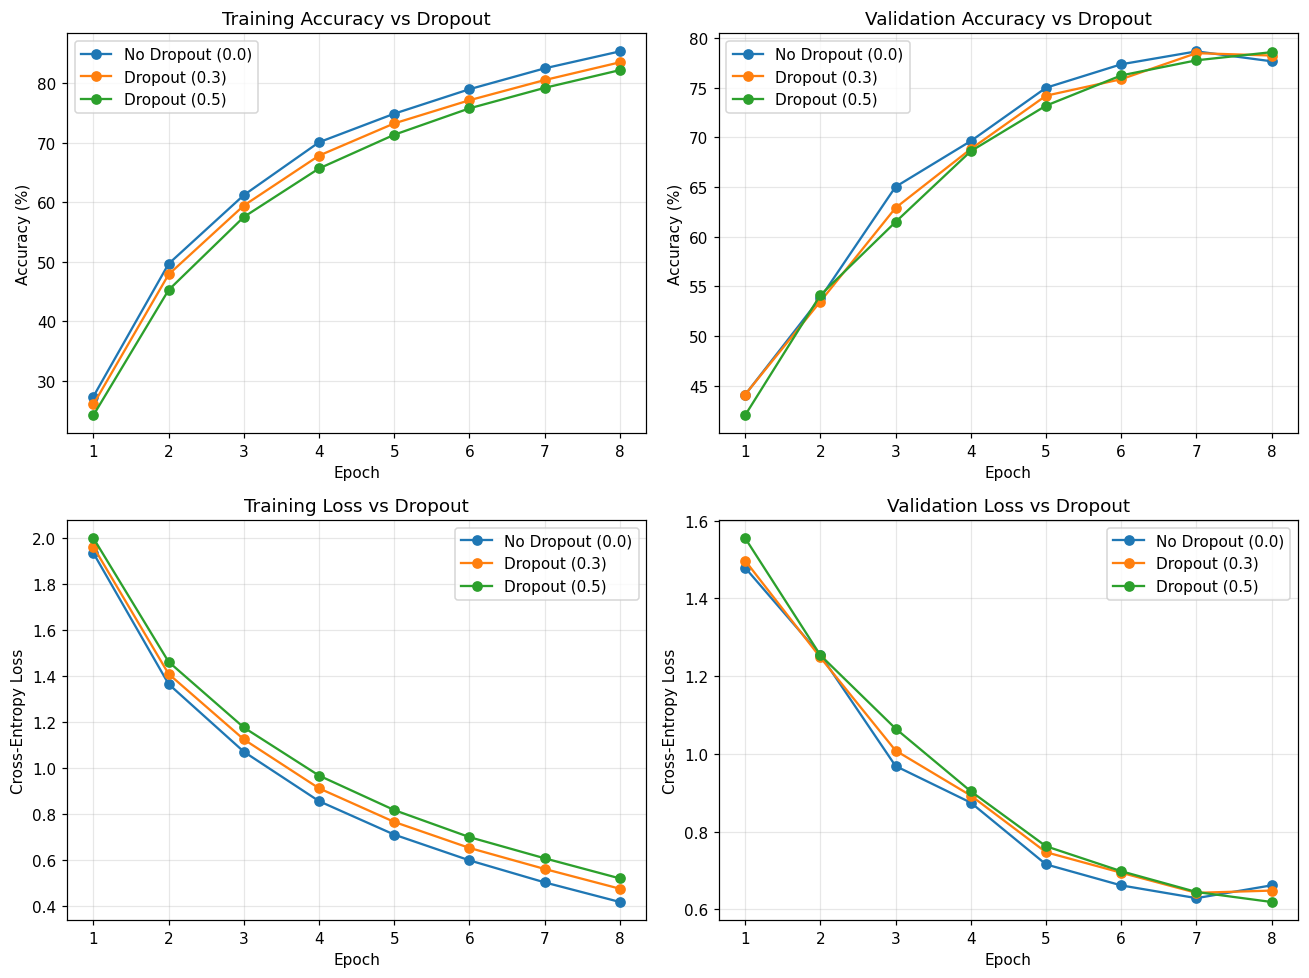

In [43]:
dropout_histories = {
    "No Dropout (0.0)": no_dropout_history,
    "Dropout (0.3)": dropout_03_history,
    "Dropout (0.5)": baseline_history
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for name, history in dropout_histories.items():
    axes[0, 0].plot(history["epoch"], history["train_accuracy"], marker="o", label=name)
    axes[0, 1].plot(history["epoch"], history["val_accuracy"], marker="o", label=name)
    axes[1, 0].plot(history["epoch"], history["train_loss"], marker="o", label=name)
    axes[1, 1].plot(history["epoch"], history["val_loss"], marker="o", label=name)

axes[0, 0].set_title("Training Accuracy vs Dropout")
axes[0, 1].set_title("Validation Accuracy vs Dropout")
axes[1, 0].set_title("Training Loss vs Dropout")
axes[1, 1].set_title("Validation Loss vs Dropout")

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy (%)" if "Accuracy" in ax.get_title() else "Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
savefig(fig, "t3_dropout_comparison")
plt.show()

Generate the Task 3 summary table

In [44]:
experiments = [
    ("Capacity", "Small", small_model, small_history),
    ("Capacity", "Baseline", baseline_model, baseline_history),
    ("Capacity", "Large", large_model, large_history),
    ("L2", "No L2", no_l2_model, no_l2_history),
    ("L2", "Strong L2", strong_l2_model, strong_l2_history),
    ("Dropout", "No Dropout", no_dropout_model, no_dropout_history),
    ("Dropout", "Dropout 0.3", dropout_03_model, dropout_03_history),
]

summary = []

for group, name, model, history in experiments:
    best_idx = history["val_accuracy"].idxmax()

    summary.append({
        "Experiment": group,
        "Configuration": name,
        "Parameters": count_parameters(model),
        "Best Val Accuracy (%)": history.loc[best_idx, "val_accuracy"],
        "Best Epoch": int(history.loc[best_idx, "epoch"]),
        "Final Train Accuracy (%)": history["train_accuracy"].iloc[-1],
        "Training Time (s)": history["seconds"].sum(),
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

,Experiment,Configuration,Parameters,Best Val Accuracy (%),Best Epoch,Final Train Accuracy (%),Training Time (s)
0,Capacity,Small,3334602,76.72,8,77.1956,68.6408
1,Capacity,Baseline,6976842,78.56,8,82.2200,80.1515
2,Capacity,Large,12750666,79.06,8,83.4200,89.1457
3,L2,No L2,6976842,79.94,8,83.9200,75.4275
4,L2,Strong L2,6976842,69.28,8,67.6378,79.1191
5,Dropout,No Dropout,6976842,78.64,7,85.3689,77.8016
6,Dropout,Dropout 0.3,6976842,78.46,7,83.5333,76.7452


Add data augmentation

In [57]:
set_seed(BASE_SEED)

augmented_model, augmented_history = train_model(
    "t4_alexnet_augmented",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS,
    weight_decay=0.0005,
    augmentation="standard"
)

t4_alexnet_augmented: Starting new training
t4_alexnet_augmented | Epoch 1/8 | Train: 21.82% | Val: 38.50% | Time: 11.2s | Peak GPU Memory: 860.7 MB
t4_alexnet_augmented | Epoch 2/8 | Train: 40.58% | Val: 49.48% | Time: 11.3s | Peak GPU Memory: 859.6 MB
t4_alexnet_augmented | Epoch 3/8 | Train: 50.63% | Val: 56.36% | Time: 9.9s | Peak GPU Memory: 859.6 MB
t4_alexnet_augmented | Epoch 4/8 | Train: 58.43% | Val: 62.82% | Time: 10.0s | Peak GPU Memory: 859.6 MB
t4_alexnet_augmented | Epoch 5/8 | Train: 64.29% | Val: 67.58% | Time: 9.7s | Peak GPU Memory: 859.6 MB
t4_alexnet_augmented | Epoch 6/8 | Train: 68.04% | Val: 71.16% | Time: 9.7s | Peak GPU Memory: 859.6 MB
t4_alexnet_augmented | Epoch 7/8 | Train: 71.68% | Val: 75.76% | Time: 10.6s | Peak GPU Memory: 859.6 MB
t4_alexnet_augmented | Epoch 8/8 | Train: 74.41% | Val: 77.56% | Time: 9.9s | Peak GPU Memory: 859.6 MB
t4_alexnet_augmented: Loaded best checkpoint (epoch 8)


Create the evaluation images

In [58]:
# Fixed evaluation images
eval_images = to_float(SPLITS["val"].x)
eval_labels = SPLITS["val"].y

# Reproducible noise
noise_gen = torch.Generator().manual_seed(42)

# Clean
clean_images = eval_images.clone()

# Rotation: 15 degrees
n = len(eval_images)
angles = torch.full((n,), 15.0)
shears = torch.zeros(n)

rotated_images = affine_batch(
    eval_images.clone(), angles, shears
)

# Gaussian noise: sigma = 0.06
noise = torch.randn(
    eval_images.shape,
    generator=noise_gen
).to(eval_images.device) * 0.06

noisy_images = (eval_images + noise).clamp(0, 1)

corrupted_sets = {
    "Clean": clean_images,
    "Rotation 15°": rotated_images,
    "Gaussian Noise": noisy_images
}

print("Evaluation images:", len(eval_labels))
print("Conditions:", list(corrupted_sets.keys()))

Evaluation images: 5000
Conditions: ['Clean', 'Rotation 15°', 'Gaussian Noise']


Evaluate both models on clean and corrupted images

In [59]:
import time

def evaluate_robustness(model, images, labels, batch_size=64):
    model.eval()
    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    correct = 0
    total = 0

    start = time.perf_counter()

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            x = images[i:i + batch_size].to(device)
            y = labels[i:i + batch_size].to(device)

            # Normalize using training statistics
            x = (x - mean) / std

            outputs = model(x)
            loss = criterion(outputs, y)

            total_loss += loss.item() * len(y)
            correct += (outputs.argmax(dim=1) == y).sum().item()
            total += len(y)

    sync()

    return {
        "accuracy": 100 * correct / total,
        "loss": total_loss / total,
        "seconds": time.perf_counter() - start
    }


# Evaluate both models
results = []

models = {
    "Original AlexNet": baseline_model,
    "Augmented AlexNet": augmented_model
}

for model_name, model in models.items():
    for corruption_name, images in corrupted_sets.items():

        metrics = evaluate_robustness(
            model,
            images,
            eval_labels
        )

        results.append({
            "Model": model_name,
            "Condition": corruption_name,
            "Accuracy (%)": metrics["accuracy"],
            "Loss": metrics["loss"],
            "Time (s)": metrics["seconds"]
        })

robustness_df = pd.DataFrame(results)

display(robustness_df)

,Model,Condition,Accuracy (%),Loss,Time (s)
0,Original AlexNet,Clean,78.56,0.6189,0.4580
1,Original AlexNet,Rotation 15°,70.32,0.8910,0.4686
2,Original AlexNet,Gaussian Noise,66.38,1.0702,0.3521
3,Augmented AlexNet,Clean,77.56,0.6531,0.7375
4,Augmented AlexNet,Rotation 15°,68.44,0.9143,0.4158
5,Augmented AlexNet,Gaussian Noise,65.06,1.0123,0.3161


Strong Augmentation

In [60]:
set_seed(BASE_SEED)

strong_aug_model, strong_aug_history = train_model(
    "t4_alexnet_strong_aug",
    AlexNet3(fc1=1024, fc2=512, dropout=0.5),
    EPOCHS,
    weight_decay=0.0005,
    augmentation="strong"
)

t4_alexnet_strong_aug: Starting new training
t4_alexnet_strong_aug | Epoch 1/8 | Train: 21.38% | Val: 38.80% | Time: 11.5s | Peak GPU Memory: 1206.8 MB
t4_alexnet_strong_aug | Epoch 2/8 | Train: 38.59% | Val: 46.88% | Time: 11.5s | Peak GPU Memory: 1206.2 MB
t4_alexnet_strong_aug | Epoch 3/8 | Train: 48.08% | Val: 55.54% | Time: 11.7s | Peak GPU Memory: 1205.7 MB
t4_alexnet_strong_aug | Epoch 4/8 | Train: 54.95% | Val: 61.06% | Time: 11.5s | Peak GPU Memory: 1205.7 MB
t4_alexnet_strong_aug | Epoch 5/8 | Train: 60.29% | Val: 66.98% | Time: 11.2s | Peak GPU Memory: 1205.7 MB
t4_alexnet_strong_aug | Epoch 6/8 | Train: 64.36% | Val: 70.22% | Time: 11.0s | Peak GPU Memory: 1205.7 MB
t4_alexnet_strong_aug | Epoch 7/8 | Train: 67.42% | Val: 71.66% | Time: 11.2s | Peak GPU Memory: 1205.7 MB
t4_alexnet_strong_aug | Epoch 8/8 | Train: 70.36% | Val: 76.40% | Time: 11.3s | Peak GPU Memory: 1205.7 MB
t4_alexnet_strong_aug: Loaded best checkpoint (epoch 8)


Evaluate the strong augmentation model

In [61]:
strong_results = []

for corruption_name, images in corrupted_sets.items():
    metrics = evaluate_robustness(
        strong_aug_model,
        images,
        eval_labels
    )

    strong_results.append({
        "Model": "Strong Augmented AlexNet",
        "Condition": corruption_name,
        "Accuracy (%)": metrics["accuracy"],
        "Loss": metrics["loss"],
        "Time (s)": metrics["seconds"]
    })

robustness_df = pd.concat(
    [robustness_df, pd.DataFrame(strong_results)],
    ignore_index=True
)

display(robustness_df)

,Model,Condition,Accuracy (%),Loss,Time (s)
0,Original AlexNet,Clean,78.56,0.6189,0.4580
1,Original AlexNet,Rotation 15°,70.32,0.8910,0.4686
2,Original AlexNet,Gaussian Noise,66.38,1.0702,0.3521
3,Augmented AlexNet,Clean,77.56,0.6531,0.7375
4,Augmented AlexNet,Rotation 15°,68.44,0.9143,0.4158
5,Augmented AlexNet,Gaussian Noise,65.06,1.0123,0.3161
6,Strong Augmented AlexNet,Clean,76.40,0.6996,0.3734
7,Strong Augmented AlexNet,Rotation 15°,71.86,0.8175,0.3060
8,Strong Augmented AlexNet,Gaussian Noise,73.74,0.7737,0.3068


Plot the robustness results

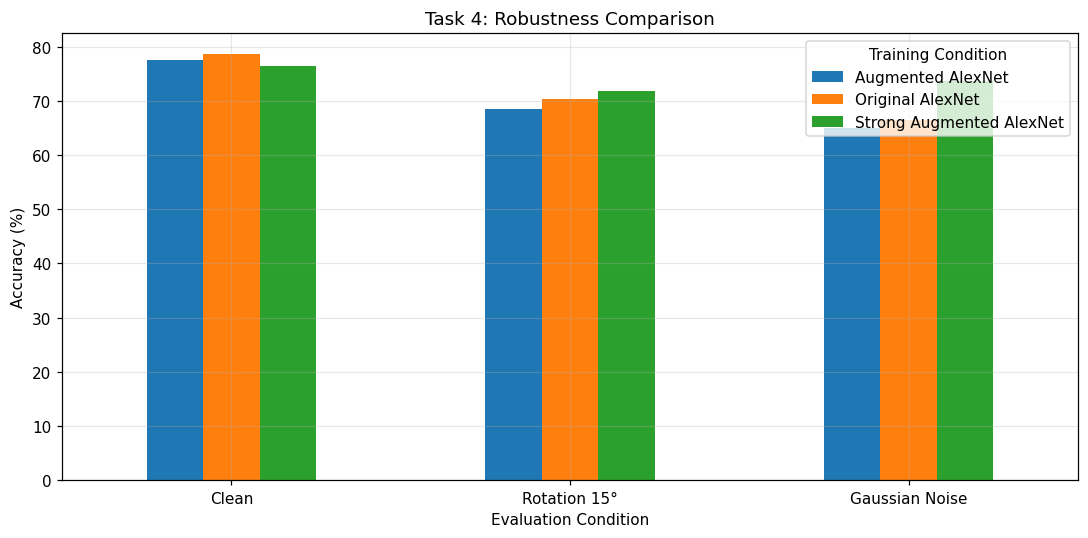

In [62]:
import matplotlib.pyplot as plt

accuracy_table = robustness_df.pivot(
    index="Condition",
    columns="Model",
    values="Accuracy (%)"
)

accuracy_table = accuracy_table.loc[
    ["Clean", "Rotation 15°", "Gaussian Noise"]
]

ax = accuracy_table.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Task 4: Robustness Comparison")
ax.set_xlabel("Evaluation Condition")
ax.set_ylabel("Accuracy (%)")
ax.legend(title="Training Condition")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
savefig(plt.gcf(), "t4_robustness_comparison")
plt.show()

Identify errors caused by corruption

In [63]:
def get_predictions(model, images, batch_size=64):
    model.eval()
    predictions = []

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            x = images[i:i + batch_size].to(device)
            x = (x - mean) / std

            outputs = model(x)
            predictions.append(outputs.argmax(dim=1).cpu())

    return torch.cat(predictions)


# Compare errors for the original and strongly augmented models
error_results = []

for model_name, model in [
    ("Original", baseline_model),
    ("Strong Augmentation", strong_aug_model)
]:
    clean_preds = get_predictions(model, corrupted_sets["Clean"])

    for condition in ["Rotation 15°", "Gaussian Noise"]:
        corrupted_preds = get_predictions(
            model,
            corrupted_sets[condition]
        )

        labels = eval_labels.cpu()

        # Correct on clean image, wrong on corrupted image
        new_errors = (
            (clean_preds == labels) &
            (corrupted_preds != labels)
        ).sum().item()

        error_results.append({
            "Model": model_name,
            "Corruption": condition,
            "New Errors": new_errors,
            "New Error Rate (%)": 100 * new_errors / len(labels)
        })

error_df = pd.DataFrame(error_results)
display(error_df)

,Model,Corruption,New Errors,New Error Rate (%)
0,Original,Rotation 15°,647,12.94
1,Original,Gaussian Noise,732,14.64
2,Strong Augmentation,Rotation 15°,443,8.86
3,Strong Augmentation,Gaussian Noise,252,5.04


Visualize the classification mistakes

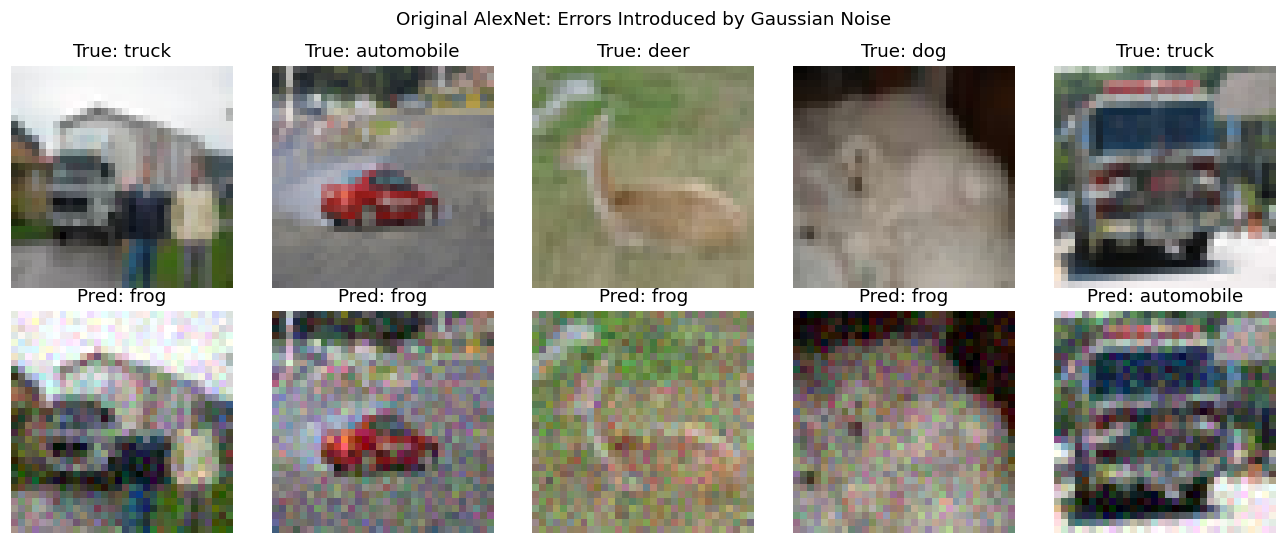

In [64]:
import matplotlib.pyplot as plt

condition = "Gaussian Noise"

clean_preds = get_predictions(baseline_model, corrupted_sets["Clean"])
corrupt_preds = get_predictions(baseline_model, corrupted_sets[condition])

labels = eval_labels.cpu()

# Images correct when clean but wrong after corruption
error_indices = torch.where(
    (clean_preds == labels) & (corrupt_preds != labels)
)[0][:5]

fig, axes = plt.subplots(2, len(error_indices), figsize=(12, 5))

for j, idx in enumerate(error_indices.tolist()):
    axes[0, j].imshow(corrupted_sets["Clean"][idx].cpu().permute(1, 2, 0))
    axes[0, j].set_title(f"True: {CLASSES[labels[idx].item()]}")
    axes[0, j].axis("off")

    axes[1, j].imshow(corrupted_sets[condition][idx].cpu().permute(1, 2, 0))
    axes[1, j].set_title(
        f"Pred: {CLASSES[corrupt_preds[idx].item()]}"
    )
    axes[1, j].axis("off")

fig.suptitle("Original AlexNet: Errors Introduced by Gaussian Noise")
plt.tight_layout()
savefig(fig, "t4_noise_error_examples")
plt.show()

Error by rotation

In [ ]:
def get_predictions(model, images, batch_size=64):
    model.eval()
    predictions = []

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            x = images[i:i + batch_size].to(device)
            x = (x - mean) / std

            outputs = model(x)
            predictions.append(outputs.argmax(dim=1).cpu())

    return torch.cat(predictions)


# Compare errors for the original and strongly augmented models
error_results = []

for model_name, model in [
    ("Original", baseline_model),
    ("Strong Augmentation", strong_aug_model)
]:
    clean_preds = get_predictions(model, corrupted_sets["Clean"])

    for condition in ["Rotation 15°", "Gaussian Noise"]:
        corrupted_preds = get_predictions(
            model,
            corrupted_sets[condition]
        )

        labels = eval_labels.cpu()

        # Correct on clean image, wrong on corrupted image
        new_errors = (
            (clean_preds == labels) &
            (corrupted_preds != labels)
        ).sum().item()

        error_results.append({
            "Model": model_name,
            "Corruption": condition,
            "New Errors": new_errors,
            "New Error Rate (%)": 100 * new_errors / len(labels)
        })

error_df = pd.DataFrame(error_results)
display(error_df)

Task 5 started, Step 1: Confusion Matrix for AlexNet and ResNet-18.


AlexNet Classification Report:
              precision    recall  f1-score   support

    airplane      0.853     0.772     0.810      1000
  automobile      0.844     0.934     0.887      1000
        bird      0.707     0.716     0.711      1000
         cat      0.627     0.623     0.625      1000
        deer      0.749     0.782     0.765      1000
         dog      0.789     0.620     0.694      1000
        frog      0.718     0.922     0.807      1000
       horse      0.831     0.842     0.837      1000
        ship      0.870     0.889     0.879      1000
       truck      0.927     0.771     0.842      1000

    accuracy                          0.787     10000
   macro avg      0.791     0.787     0.786     10000
weighted avg      0.791     0.787     0.786     10000


ResNet18 Classification Report:
              precision    recall  f1-score   support

    airplane      0.854     0.809     0.831      1000
  automobile      0.893     0.927     0.910      1000
        bird 

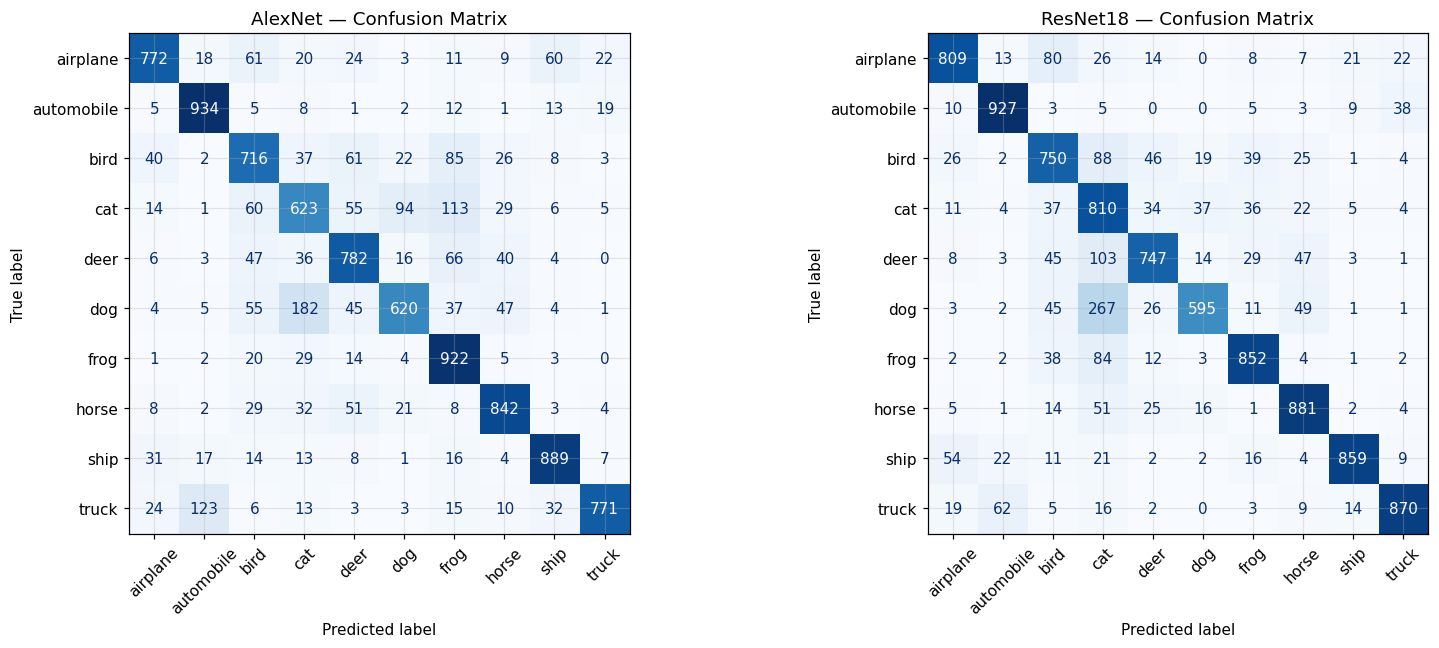

In [85]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Use the official CIFAR-10 test set
test_images = to_float(SPLITS["test"].x)
test_labels = SPLITS["test"].y.cpu().numpy()

models = {
    "AlexNet": alexnet,
    "ResNet18": resnet
}

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (name, model) in zip(axes, models.items()):

    # Reuse the prediction function from Task 4
    predictions = get_predictions(
        model, test_images
    ).numpy()

    # Calculate confusion matrix
    cm = confusion_matrix(test_labels, predictions)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASSES
    ).plot(ax=ax, cmap="Blues", colorbar=False)

    ax.set_title(f"{name} — Confusion Matrix")
    ax.tick_params(axis="x", labelrotation=45)

    print(f"\n{name} Classification Report:")
    print(classification_report(
        test_labels,
        predictions,
        target_names=CLASSES,
        digits=3
    ))

plt.tight_layout()
savefig(fig, "t5_confusion_matrices")
plt.show()

Inspect actual predictions

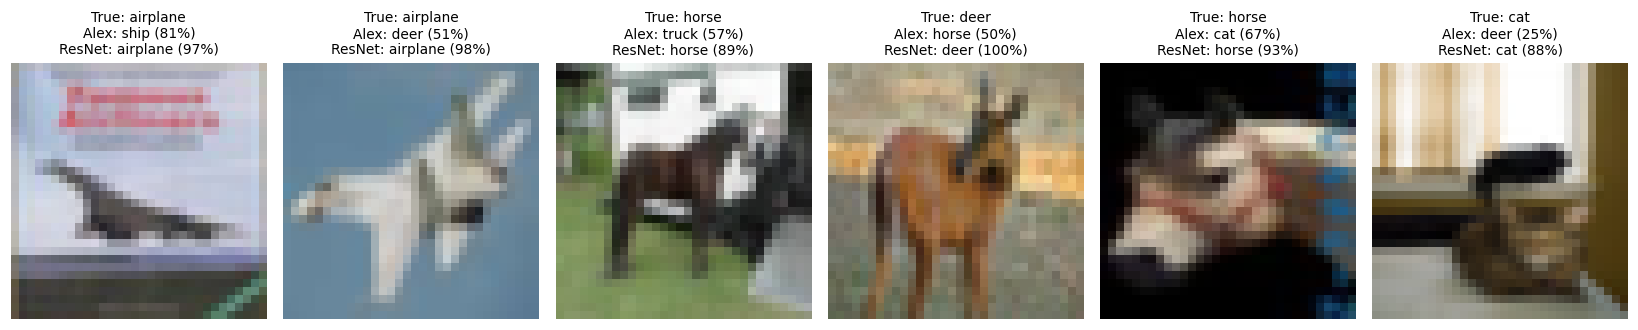

In [86]:
import torch
import matplotlib.pyplot as plt

def predict_with_confidence(model, images, batch_size=64):
    model.eval()
    all_predictions = []
    all_confidences = []

    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            x = images[i:i + batch_size].to(device)
            x = (x - mean) / std

            probabilities = torch.softmax(model(x), dim=1)
            confidence, prediction = probabilities.max(dim=1)

            all_predictions.append(prediction.cpu())
            all_confidences.append(confidence.cpu())

    return torch.cat(all_predictions), torch.cat(all_confidences)


test_images = to_float(SPLITS["test"].x)
test_labels = SPLITS["test"].y.cpu()

alex_preds, alex_conf = predict_with_confidence(alexnet, test_images)
res_preds, res_conf = predict_with_confidence(resnet, test_images)

# Cases where AlexNet is wrong, but ResNet is correct
indices = torch.where(
    (alex_preds != test_labels) &
    (res_preds == test_labels)
)[0][:6]

fig, axes = plt.subplots(1, len(indices), figsize=(15, 3))

for ax, idx in zip(axes, indices.tolist()):
    ax.imshow(test_images[idx].cpu().permute(1, 2, 0))
    ax.set_title(
        f"True: {CLASSES[test_labels[idx].item()]}\n"
        f"Alex: {CLASSES[alex_preds[idx].item()]} ({alex_conf[idx]:.0%})\n"
        f"ResNet: {CLASSES[res_preds[idx].item()]} ({res_conf[idx]:.0%})",
        fontsize=9
    )
    ax.axis("off")

plt.tight_layout()
savefig(fig, "t5_prediction_examples")
plt.show()

Visualize correct and incorrect predictions for both AlexNet and ResNet-18

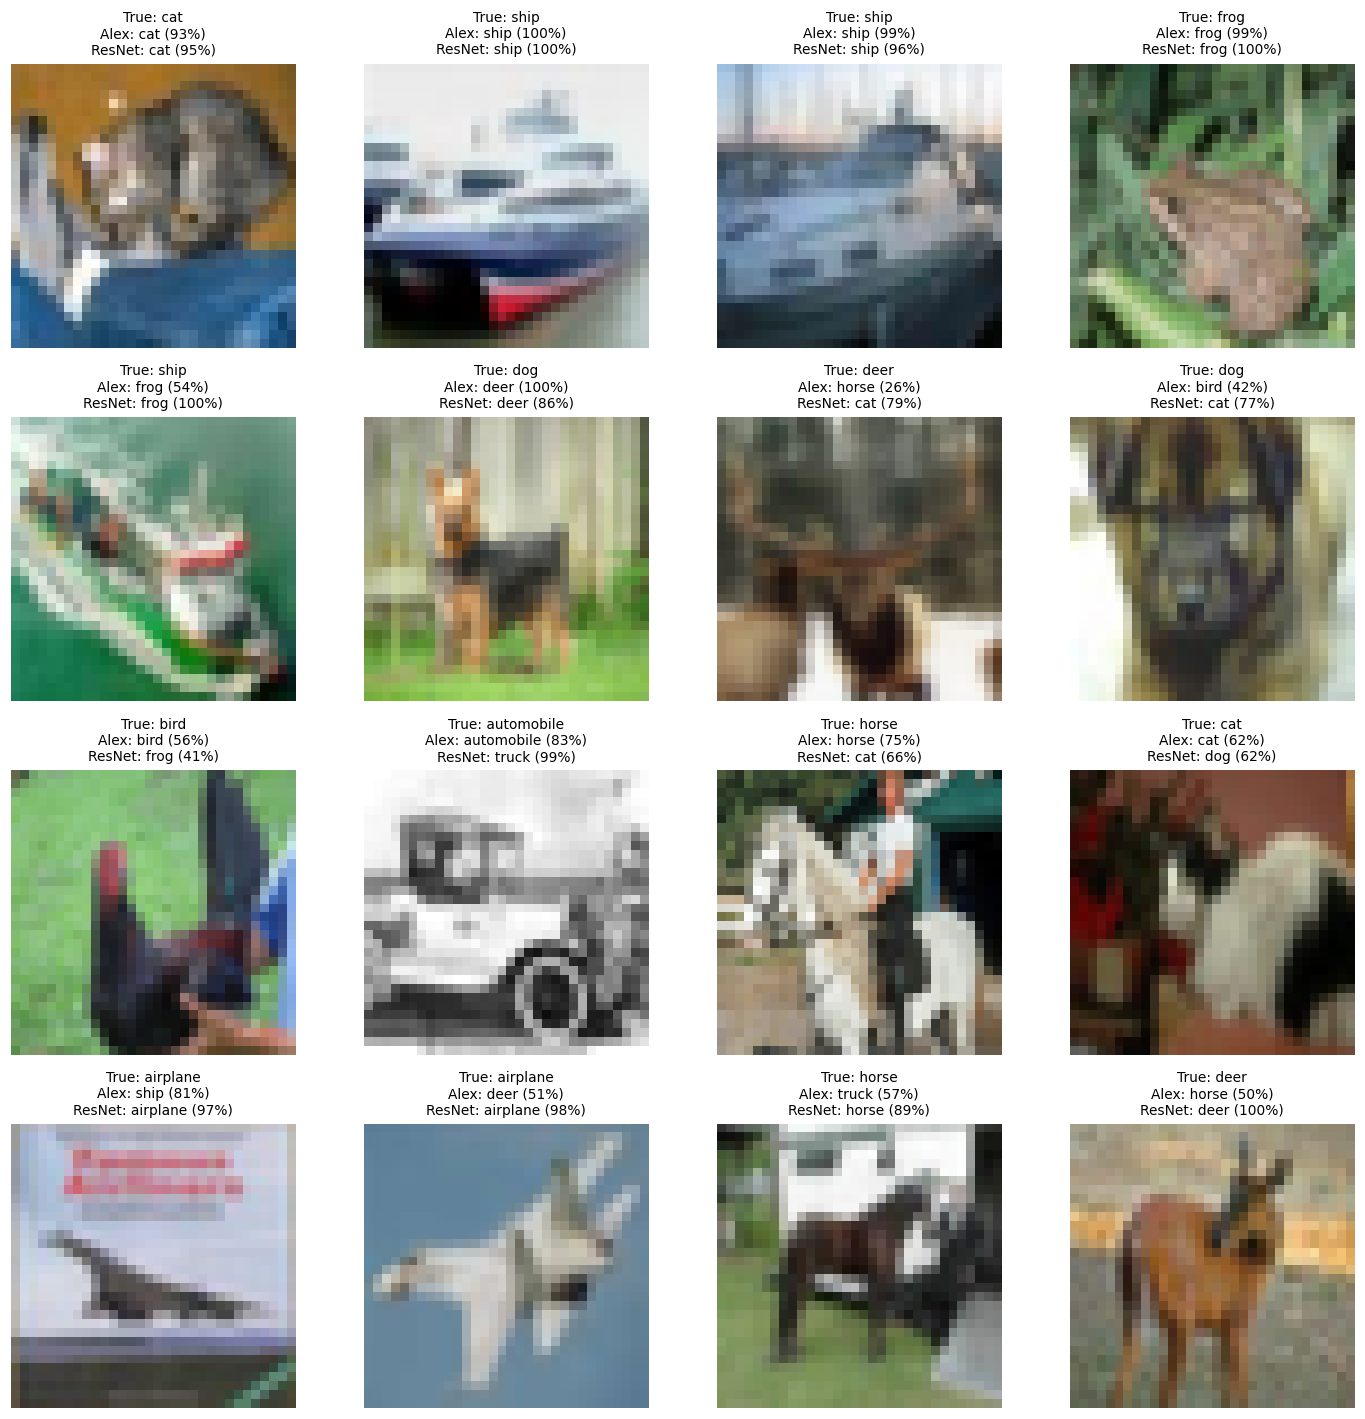

In [87]:
import matplotlib.pyplot as plt

categories = {
    "Both correct": (alex_preds == test_labels) & (res_preds == test_labels),
    "Both incorrect": (alex_preds != test_labels) & (res_preds != test_labels),
    "Only AlexNet correct": (alex_preds == test_labels) & (res_preds != test_labels),
    "Only ResNet18 correct": (alex_preds != test_labels) & (res_preds == test_labels)
}

fig, axes = plt.subplots(4, 4, figsize=(13, 13))

for row, (category, mask) in enumerate(categories.items()):
    indices = torch.where(mask)[0][:4]

    for col, idx in enumerate(indices.tolist()):
        ax = axes[row, col]

        ax.imshow(test_images[idx].cpu().permute(1, 2, 0))

        ax.set_title(
            f"True: {CLASSES[test_labels[idx].item()]}\n"
            f"Alex: {CLASSES[alex_preds[idx].item()]} ({alex_conf[idx]:.0%})\n"
            f"ResNet: {CLASSES[res_preds[idx].item()]} ({res_conf[idx]:.0%})",
            fontsize=9
        )
        ax.axis("off")

    axes[row, 0].set_ylabel(category, fontsize=11)

plt.tight_layout()
savefig(fig, "t5_prediction_categories")
plt.show()

Define the FGSM attack

In [88]:

def fgsm_attack(model, images, labels, epsilon):
    model.eval()

    # Images must be in [0, 1]
    x = images.clone().detach().to(device)
    y = labels.to(device)

    # Enable gradients for the input images
    x.requires_grad_(True)

    # Normalize before passing through the model
    normalized = (x - mean) / std

    outputs = model(normalized)
    loss = nn.functional.cross_entropy(outputs, y)

    # Gradient of loss with respect to input pixels
    gradient = torch.autograd.grad(loss, x)[0]

    # Generate adversarial images
    adversarial = x + epsilon * gradient.sign()

    # Keep valid pixel values
    adversarial = adversarial.clamp(0, 1).detach()

    return adversarial


Verify FGSM on a small batch

In [89]:

# Take 8 official test images
x = to_float(SPLITS["test"].x[:8])
y = SPLITS["test"].y[:8]

# Generate adversarial examples against AlexNet
x_adv = fgsm_attack(
    alexnet,
    x,
    y,
    epsilon=0.03
)

print("Original shape:", x.shape)
print("Adversarial shape:", x_adv.shape)
print("Pixel range:", x_adv.min().item(), x_adv.max().item())
print("Maximum pixel change:", (x_adv - x).abs().max().item())


Original shape: torch.Size([8, 3, 32, 32])
Adversarial shape: torch.Size([8, 3, 32, 32])
Pixel range: 0.0 1.0
Maximum pixel change: 0.030000001192092896


Evaluate FGSM on both models

In [90]:

# FGSM evaluation settings
epsilons = [0.0, 0.01, 0.03, 0.05]
attack_n = P["attack_n"]

# Use the same test images for both models
attack_images = to_float(SPLITS["test"].x[:attack_n])
attack_labels = SPLITS["test"].y[:attack_n]

fgsm_results = []

for model_name, model in [
    ("AlexNet", alexnet),
    ("ResNet18", resnet)
]:
    model.eval()

    for epsilon in epsilons:
        correct = 0
        total = 0

        for i in range(0, attack_n, BATCH_SIZE):
            x = attack_images[i:i + BATCH_SIZE]
            y = attack_labels[i:i + BATCH_SIZE]

            # FGSM creates adversarial images for this model
            x_adv = fgsm_attack(model, x, y, epsilon)

            # Evaluate the attacked images
            with torch.no_grad():
                outputs = model((x_adv - mean) / std)
                predictions = outputs.argmax(dim=1)

            correct += (predictions == y).sum().item()
            total += len(y)

        accuracy = 100 * correct / total

        fgsm_results.append({
            "Model": model_name,
            "Epsilon": epsilon,
            "Accuracy (%)": accuracy
        })

fgsm_df = pd.DataFrame(fgsm_results)

display(fgsm_df)


,Model,Epsilon,Accuracy (%)
0,AlexNet,0.00,76.4
1,AlexNet,0.01,37.0
2,AlexNet,0.03,6.8
3,AlexNet,0.05,2.0
4,ResNet18,0.00,81.0
5,ResNet18,0.01,14.2
6,ResNet18,0.03,1.8
7,ResNet18,0.05,0.8


Visualize FGSM adversarial images

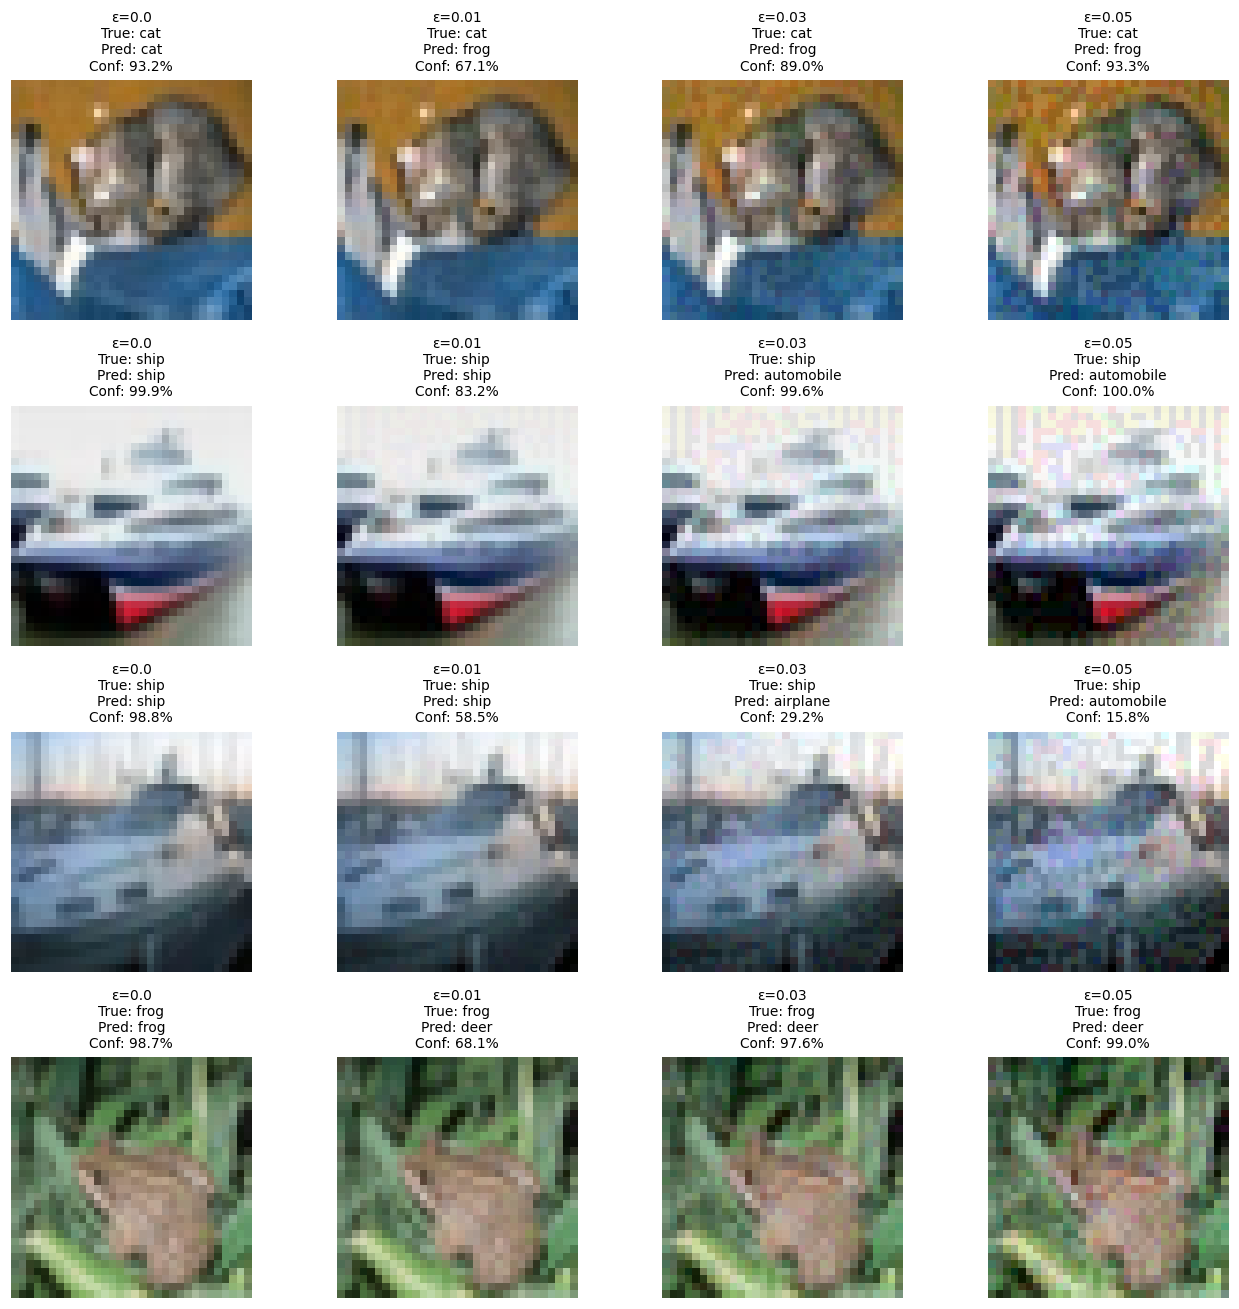

In [91]:

import matplotlib.pyplot as plt

epsilons = [0.0, 0.01, 0.03, 0.05]

# Select 4 test images that AlexNet classifies correctly
test_x = to_float(SPLITS["test"].x[:100])
test_y = SPLITS["test"].y[:100]

alexnet.eval()

with torch.no_grad():
    outputs = alexnet((test_x - mean) / std)
    predictions = outputs.argmax(dim=1)

correct_indices = torch.where(predictions == test_y)[0][:4]

fig, axes = plt.subplots(4, 4, figsize=(12, 12))

for row, idx in enumerate(correct_indices.tolist()):
    x = test_x[idx:idx+1]
    y = test_y[idx:idx+1]

    for col, epsilon in enumerate(epsilons):

        # Generate FGSM adversarial image
        x_adv = fgsm_attack(alexnet, x, y, epsilon)

        # Predict the modified image
        with torch.no_grad():
            probabilities = torch.softmax(
                alexnet((x_adv - mean) / std), dim=1
            )

            confidence, prediction = probabilities.max(dim=1)

        axes[row, col].imshow(
            x_adv[0].detach().cpu().permute(1, 2, 0).numpy()
        )

        axes[row, col].set_title(
            f"ε={epsilon}\n"
            f"True: {CLASSES[y.item()]}\n"
            f"Pred: {CLASSES[prediction.item()]}\n"
            f"Conf: {confidence.item():.1%}",
            fontsize=9
        )
        axes[row, col].axis("off")

plt.tight_layout()
savefig(fig, "t5_fgsm_examples")
plt.show()
